# DATA MINING - PROJECT

## 1. Preparation

In [ ]:
!pip install datasets -q

In [ ]:
# Import Libraries
import datasets
import pandas as pd

In [ ]:
# Load the AG News Datasets
ag_news = datasets.load_dataset("fancyzhx/ag_news")

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [ ]:
# Preview the AG News Datasets Structure
ag_news

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

In [ ]:
# Convert the datasets into pandas DataFrames
train_ds = ag_news["train"]
df_train = train_ds.to_pandas()

test_ds = ag_news["test"]
df_test = test_ds.to_pandas()

In [ ]:
# Check the dimensions of both datasets
print(df_test.shape)
print(df_train.shape)

(7600, 2)
(120000, 2)


In [ ]:
# Preview the first five rows of each dataset
print(df_test.head())
print(df_train.head())

                                                text  label
0  Fears for T N pension after talks Unions repre...      2
1  The Race is On: Second Private Team Sets Launc...      3
2  Ky. Company Wins Grant to Study Peptides (AP) ...      3
3  Prediction Unit Helps Forecast Wildfires (AP) ...      3
4  Calif. Aims to Limit Farm-Related Smog (AP) AP...      3
                                                text  label
0  Wall St. Bears Claw Back Into the Black (Reute...      2
1  Carlyle Looks Toward Commercial Aerospace (Reu...      2
2  Oil and Economy Cloud Stocks' Outlook (Reuters...      2
3  Iraq Halts Oil Exports from Main Southern Pipe...      2
4  Oil prices soar to all-time record, posing new...      2


In [ ]:
print(df_train.info())
print()
print(df_test.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    120000 non-null  object
 1   label   120000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 1.8+ MB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7600 entries, 0 to 7599
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    7600 non-null   object
 1   label   7600 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.9+ KB
None


In [ ]:
label_mapping = {0: "World", 1: "Sports", 2: "Business",3: "Sci/Tech"}

df_train["category"] = df_train["label"].map(label_mapping)
df_test["category"] = df_test["label"].map(label_mapping)

print(df_train[["text", "label", "category"]].head())
print(df_test[["text", "label", "category"]].head())

                                                text  label  category
0  Wall St. Bears Claw Back Into the Black (Reute...      2  Business
1  Carlyle Looks Toward Commercial Aerospace (Reu...      2  Business
2  Oil and Economy Cloud Stocks' Outlook (Reuters...      2  Business
3  Iraq Halts Oil Exports from Main Southern Pipe...      2  Business
4  Oil prices soar to all-time record, posing new...      2  Business
                                                text  label  category
0  Fears for T N pension after talks Unions repre...      2  Business
1  The Race is On: Second Private Team Sets Launc...      3  Sci/Tech
2  Ky. Company Wins Grant to Study Peptides (AP) ...      3  Sci/Tech
3  Prediction Unit Helps Forecast Wildfires (AP) ...      3  Sci/Tech
4  Calif. Aims to Limit Farm-Related Smog (AP) AP...      3  Sci/Tech


## 2. EDA

In [ ]:
# Calculate the total for each news category
total_each_category = df_train["category"].value_counts()

print(total_each_category)

category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


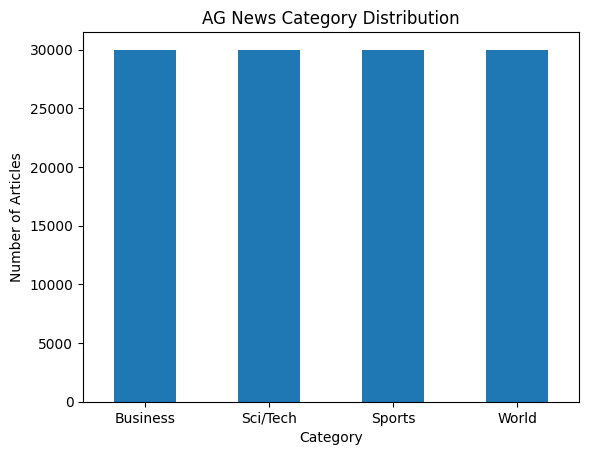

In [ ]:
# Visualize the category distribution in the training dataset
import matplotlib.pyplot as plt

total_each_category.plot(kind="bar")

plt.title("AG News Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.show()

The AG News training dataset contains four categories: World, Sports, Business, and Sci/Tech. Each category has 30,000 articles, representing 25% of the total dataset. Therefore, the dataset has a balanced class distribution, with no significant class imbalance.

Since all classes have an equal number of samples, accuracy can be used as one of the evaluation metrics. However, precision, recall, and F1-score should also be considered to provide a more comprehensive evaluation of the classification model.

In [ ]:
# Calculate the number of characters in each article
df_train["length"] = df_train["text"].str.len()

# Calculate the number of words in each article
df_train["word_count"] = df_train["text"].str.split().str.len()

df_train[["length", "word_count"]].head()

,length,word_count
0,144,21
1,266,36
2,232,36
3,256,36
4,234,37


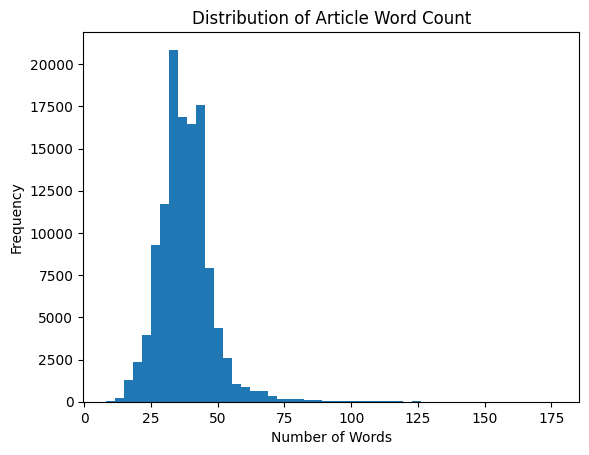

In [ ]:
# Visualize the distribution of article word counts
df_train["word_count"].plot(kind="hist", bins=50)

plt.title("Distribution of Article Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Sort and compare the average article word count across categories
df_train.groupby("category")["word_count"].mean().sort_values(ascending=False)


,word_count
category,
World,38.884867
Sports,37.774733
Business,37.538233
Sci/Tech,37.191967


In [ ]:
# Check duplicate articles
print("Train duplicates:", df_train["text"].duplicated().sum())
print("Test duplicates:", df_test["text"].duplicated().sum())

# Check overlap between train and test
overlap = set(df_train["text"]) & set(df_test["text"])

print("Train-Test overlap:", len(overlap))

Train duplicates: 0
Test duplicates: 0
Train-Test overlap: 0


In [ ]:
# Inspect sample articles from each category for HTML entities and formatting issues
for category in df_train["category"].unique():

    print(f"\n========== {category} ==========")

    samples = df_train[df_train["category"] == category]["text"].sample(3, random_state=42)

    for i, text in enumerate(samples, 1):
        print(f"\nSample {i}:")
        print(text)


========== Business ==========

Sample 1:
US house sales fall in July Sales of non-new houses in the US fell last month but still exceeded analyst forecasts.

Sample 2:
DJ to acquire MarketWatch Dow Jones  amp; Co., publisher of the Wall Street Journal, says it has agreed to buy online news site MarketWatch Inc. in a \$519 million deal that widens its Internet audience.

Sample 3:
Dollar hits new low on Snow speech The United States supports a  quot;strong dollar, quot; Treasury Secretary John Snow said, while suggesting the Bush administration will not act to boost its value. His comments sent the currency plunging to a record low against the euro.

========== Sci/Tech ==========

Sample 1:
Gartner optimistic about chip numbers But that optimism isn #39;t matched by Infineon, which said that while the market worldwide remains buoyant, the US is a special case and cautioned that growth might not be as strong as it expected.

Sample 2:
Fossil Indicates Brown Bears Went South CALGARY, A

In [ ]:
# Import Additional Libraries
from collections import Counter
import re
import html

In [ ]:
for category in df_train["category"].unique():

    # Select text based on category
    texts = df_train[df_train["category"] == category]["text"]

    # Combine all text
    all_text = " ".join(texts).lower()

    # Split into words
    words = all_text.split()

    # Count word frequency
    word_counts = Counter(words)

    print(f"\n===== {category} =====")
    print(word_counts.most_common(20))


===== Business =====
[('the', 44299), ('to', 29714), ('a', 24957), ('of', 22628), ('in', 22048), ('and', 16939), ('on', 16387), ('for', 12052), ('its', 9487), ('-', 9010), ('#39;s', 8939), ('as', 8198), ('that', 7232), ('said', 6655), ('new', 6505), ('it', 6212), ('oil', 6050), ('by', 5986), ('(reuters)', 5561), ('us', 5547)]

===== Sci/Tech =====
[('the', 47252), ('to', 31065), ('a', 26198), ('of', 26184), ('and', 18588), ('in', 17377), ('for', 12792), ('on', 11824), ('that', 9206), ('-', 7853), ('is', 7848), ('its', 7770), ('with', 7189), ('new', 7015), ('#39;s', 6098), ('has', 6083), ('it', 6023), ('by', 5307), ('as', 4990), ('at', 4598)]

===== Sports =====
[('the', 63136), ('to', 27385), ('a', 25752), ('in', 23863), ('of', 20232), ('and', 15651), ('for', 13776), ('on', 12209), ('#39;s', 9508), ('at', 9304), ('-', 8728), ('with', 8395), ('his', 7836), ('as', 5740), ('was', 5285), ('is', 4768), ('after', 4535), ('he', 4534), ('that', 4386), ('has', 4126)]

===== World =====
[('the'

In [ ]:
# Count news-agency tags (Reuters, AP, AFP) in each category
source_patterns = {
    "Reuters": r"\(Reuters\)|\bReuters\s*-",
    "AP": r"\(AP\)|\bAP\s*-",
    "AFP": r"\(AFP\)|\bAFP\s*-"
}

source_counts = pd.DataFrame({
    source: df_train.groupby("category")["text"].apply(lambda texts: texts.str.contains(pattern, regex=True).sum())
    for source, pattern in source_patterns.items()
})

# Percentage of articles in each category that contain the tag
source_share = (source_counts.div(total_each_category, axis=0) * 100).round(2)

print("Number of articles with news-agency tags:")
display(source_counts)

print("Percentage of articles in each category (%):")
display(source_share)

Number of articles with news-agency tags:


,Reuters,AP,AFP
category,,,
Business,5557,241,326
Sci/Tech,1922,2028,207
Sports,1424,3104,157
World,3900,2941,1812


Percentage of articles in each category (%):


,Reuters,AP,AFP
category,,,
Business,18.52,0.80,1.09
Sci/Tech,6.41,6.76,0.69
Sports,4.75,10.35,0.52
World,13.00,9.80,6.04


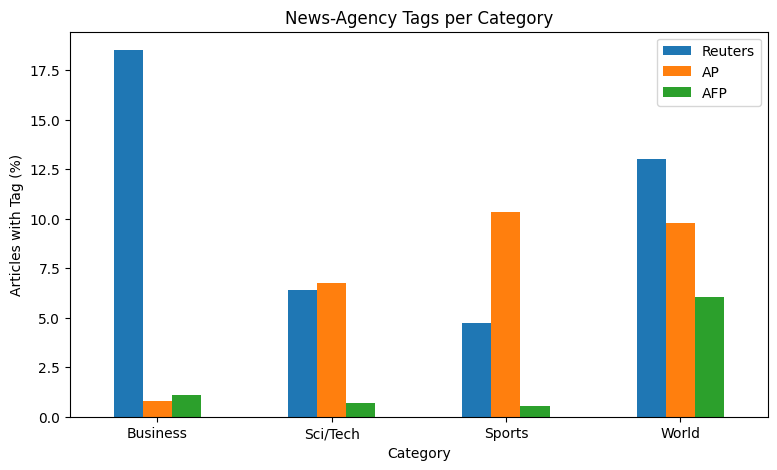

In [ ]:
# Visualize the share of news-agency tags in each category
source_share.plot(kind="bar", figsize=(9, 5))

plt.title("News-Agency Tags per Category")
plt.xlabel("Category")
plt.ylabel("Articles with Tag (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Check pseudo-HTML tags, URLs, and email addresses in the raw articles
noise_patterns = {
    "HTML Tag": r"&lt;|<[^>]+>",
    "URL": r"https?://|www\.",
    "Email": r"[\w.+-]+@[\w-]+\.[\w.]+"
}

noise_counts = pd.DataFrame({
    noise: df_train.groupby("category")["text"].apply(lambda texts: texts.str.contains(pattern, case=False, regex=True).sum())
    for noise, pattern in noise_patterns.items()
})

display(noise_counts)

print("Total articles with each noise type:")
print(noise_counts.sum())

,HTML Tag,URL,Email
category,,,
Business,2238,1539,0
Sci/Tech,1415,304,0
Sports,631,4,0
World,957,0,0


Total articles with each noise type:
HTML Tag    5241
URL         1847
Email          0
dtype: int64


Besides the balanced classes, the EDA found two kinds of noise that could become shortcuts for the model:

- **News-agency tags are not spread evenly.** Reuters appears in 18.52% of Business articles but only 4.75% of Sports articles, while AP appears in 10.35% of Sports articles but only 0.80% of Business articles. A model could learn *who wrote the article* instead of *what the article is about*, so these tags are removed during preprocessing.
- **Pseudo-HTML tags and URLs.** 5,241 training articles contain HTML tags (for example `&lt;b&gt;` or `<a href=...>`) and 1,847 contain URLs. URLs are concentrated in Business (1,539) and Sci/Tech (304), and are almost absent in Sports (4) and World (0), so they would act as the same kind of shortcut. No email addresses were found. Tags and URLs are removed during preprocessing, as planned in the proposal.

## 3. Data Preprocessing

In [ ]:
def clean_text(text):
    # 1. Decode standard HTML entities
    text = html.unescape(text)

    # 2. Fix remaining HTML entity fragments
    text = text.replace("#39;", "'")
    text = re.sub(r"(?<=\s)amp;", "&", text, flags=re.IGNORECASE)
    text = re.sub(r"(?<=\s)quot;", '"', text, flags=re.IGNORECASE)
    text = re.sub(r"(?<=\s)(?:lt|gt);", " ", text, flags=re.IGNORECASE)

    # 3. Remove pseudo-HTML tags: <b>, <p>, <a href=...>, </strong>
    text = re.sub(r"<[^>]+>", " ", text)

    # 4. Remove URLs and email addresses
    text = re.sub(r"https?://\S*|www\.\S*", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", " ", text)

    # 5. Remove source attribution inside parentheses: (AP-CP), (Reuters)
    text = re.sub(r"\s*\((?:Reuters|AP|AFP)(?:-[A-Za-z]+)?\)", "", text, flags=re.IGNORECASE)

    # 6. Remove source attribution after title: AP - / Reuters -
    text = re.sub(r"\s+\b(?:Reuters|AP|AFP)\s*-\s*", " ", text, flags=re.IGNORECASE)

    # 7. Remove incomplete parenthesized attribution: (AFP -
    text = re.sub(r"\s*\((?:Reuters|AP|AFP)\s*-\s*", " ", text, flags=re.IGNORECASE)

    # 8. Remove news codes at the beginning: AP-Italy-Alitalia
    text = re.sub(r"^(?:AP|AFP|Reuters)-[A-Za-z0-9]+(?:-[A-Za-z0-9]+)*\s+", "", text, flags=re.IGNORECASE)

    # 9. Remove source attribution after a slash: UC Davis/AP --
    text = re.sub(r"/(?:Reuters|AP|AFP)\s*--?\s*", " ", text, flags=re.IGNORECASE)

    # 10. Remove escaped dollar signs and remaining backslashes
    text = text.replace("\\$", "$")
    text = text.replace("\\", " ")

    # 11. Lowercase
    text = text.lower()

    # 12. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
samples = df_train["text"].iloc[:10]

for text in samples:
    print("Before Preprocess:", text)
    print("After Preprocess :", clean_text(text))
    print("-" * 100)

Before Preprocess: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
After Preprocess : wall st. bears claw back into the black short-sellers, wall street's dwindling band of ultra-cynics, are seeing green again.
----------------------------------------------------------------------------------------------------
Before Preprocess: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.
After Preprocess : carlyle looks toward commercial aerospace private investment firm carlyle group, which has a reputation for making well-timed and occasionally controversial plays in the defense industry, has quietly placed its bets on another part of the market.
---------------------------------------

In [ ]:
# Apply the text-cleaning function to both datasets
df_train["clean_text"] = df_train["text"].apply(clean_text)
df_test["clean_text"] = df_test["text"].apply(clean_text)

In [ ]:
# Verify that HTML tags, URLs, emails, and news-agency tags were removed
check_patterns = {
    "HTML Tag": r"<[^>]+>",
    "URL": r"https?://|www\.",
    "Email": r"[\w.+-]+@[\w-]+\.[\w.]+",
    "News-Agency Tag": r"\b(?:reuters|ap|afp)\b\s*-"
}

for name, pattern in check_patterns.items():
    remaining_train = df_train["clean_text"].str.contains(pattern, regex=True).sum()
    remaining_test = df_test["clean_text"].str.contains(pattern, regex=True).sum()

    print(f"{name:16s} -> train: {remaining_train}, test: {remaining_test}")

HTML Tag         -> train: 0, test: 0
URL              -> train: 0, test: 0
Email            -> train: 0, test: 0
News-Agency Tag  -> train: 0, test: 0


In [ ]:
# Check whether preprocessing produced any empty articles
print("Empty train:", (df_train["clean_text"] == "").sum())
print("Empty test:", (df_test["clean_text"] == "").sum())

Empty train: 0
Empty test: 0


In [ ]:
# Count duplicate cleaned articles in each dataset
print("Train duplicates:", df_train["clean_text"].duplicated().sum())
print("Test duplicates:", df_test["clean_text"].duplicated().sum())

Train duplicates: 578
Test duplicates: 0


In [ ]:
# Identify duplicate article texts that are associated with multiple labels
duplicate_labels = (df_train[df_train["clean_text"].duplicated(keep=False)].groupby("clean_text")["label"].nunique())

print("Duplicates with conflicting labels:", (duplicate_labels > 1).sum())

Duplicates with conflicting labels: 70


In [ ]:
# Print the article texts that have conflicting labels
conflicting_texts = duplicate_labels[duplicate_labels > 1].index

conflicting_samples = df_train[df_train["clean_text"].isin(conflicting_texts)].sort_values("clean_text")

print(conflicting_samples[["clean_text", "label", "category"]].head(20))

                                               clean_text  label  category
117744  abn amro leads european shares higher european...      2  Business
117704  abn amro leads european shares higher european...      0     World
33834   adobe posts sharp rise in profit adobe systems...      2  Business
33809   adobe posts sharp rise in profit adobe systems...      3  Sci/Tech
4671    amazon to purchase chinese on-line retailer am...      2  Business
5653    amazon to purchase chinese on-line retailer am...      3  Sci/Tech
76100   amd introduces low-cost net access device in i...      3  Sci/Tech
76153   amd introduces low-cost net access device in i...      0     World
67242   at t posts $7.1 billion loss on writedown wash...      3  Sci/Tech
67231   at t posts $7.1 billion loss on writedown wash...      2  Business
70117   brazil launches first rocket into space brazil...      0     World
70025   brazil launches first rocket into space brazil...      3  Sci/Tech
94241   brazil upset in e

In [ ]:
# Remove all conflicting texts
df_train = df_train[~df_train["clean_text"].isin(conflicting_texts)].copy()

# Remove remaining duplicates with consistent labels
df_train = df_train.drop_duplicates(subset="clean_text",keep="first").copy()

print("Train duplicates after cleaning:", df_train["clean_text"].duplicated().sum())

Train duplicates after cleaning: 0


In [ ]:
# Identify exact text overlap between the cleaned training and test datasets
train_test_overlap = (set(df_train["clean_text"]) & set(df_test["clean_text"]))

print("Train-Test overlap:", len(train_test_overlap))

Train-Test overlap: 53


In [ ]:
overlap = (set(df_train["clean_text"]) & set(df_test["clean_text"]))

# Remove overlapping articles from the training dataset while preserving the test dataset
df_train = df_train[~df_train["clean_text"].isin(overlap)].copy()

print("Train-Test overlap after cleaning:", len(set(df_train["clean_text"]) & set(df_test["clean_text"])))

Train-Test overlap after cleaning: 0


In [ ]:
# Original dataset size
train_before = len(ag_news["train"])
test_before = len(ag_news["test"])

# Dataset size after preprocessing
train_after = len(df_train)
test_after = len(df_test)

# Create summary table
summary = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "Before Preprocessing": [train_before, test_before],
    "After Preprocessing": [train_after, test_after],
    "Removed": [
        train_before - train_after,
        test_before - test_after
    ]
})

summary

,Dataset,Before Preprocessing,After Preprocessing,Removed
0,Train,120000,119299,701
1,Test,7600,7600,0


## 4. Data Transformation

In [ ]:
x_train = df_train["clean_text"]
y_train = df_train["label"]

x_test = df_test["clean_text"]
y_test = df_test["label"]

In [ ]:
print("X Train : ", x_train.shape)
print("Y Train :", y_train.shape)

print("X Test:", x_test.shape)
print("Y Test:", y_test.shape)

X Train :  (119299,)
Y Train : (119299,)
X Test: (7600,)
Y Test: (7600,)


In [ ]:
# Import Additional Libraries again
import time
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [ ]:
x_fit, x_val, y_fit, y_val = train_test_split(x_train, y_train, test_size=0.1, stratify=y_train, random_state=42)

In [ ]:
print("X_fit:", x_fit.shape)
print("X_val:", x_val.shape)
print("Y_fit:", y_fit.shape)
print("Y_val:", y_val.shape)

X_fit: (107369,)
X_val: (11930,)
Y_fit: (107369,)
Y_val: (11930,)


In [ ]:
vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words="english",
    sublinear_tf=True
)

# Fit and transform training data
x_fit_tfidf = vectorizer.fit_transform(x_fit)

# Transform validation and testing data
x_val_tfidf = vectorizer.transform(x_val)
x_test_tfidf = vectorizer.transform(x_test)

In [ ]:
print("X_fit_tfidf:", x_fit_tfidf.shape)
print("X_val_tfidf:", x_val_tfidf.shape)
print("X_test_tfidf:", x_test_tfidf.shape)

X_fit_tfidf: (107369, 50000)
X_val_tfidf: (11930, 50000)
X_test_tfidf: (7600, 50000)


In [ ]:
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))
print(vectorizer.get_feature_names_out()[:20])

Vocabulary size: 50000
['00' '00 pm' '00 pt' '000' '000 000' '000 20' '000 ac' '000 barrels'
 '000 customers' '000 dead' '000 dodge' '000 dollar' '000 dollars'
 '000 employees' '000 fans' '000 feet' '000 fine' '000 gallons'
 '000 homes' '000 iraqi']


TF-IDF was used to convert news articles into numerical feature representations. The vectorizer was configured with a maximum of 50,000 features, unigram and bigram extraction, a minimum document frequency of 2, a maximum document frequency of 95%, English stopword removal, and sublinear term frequency scaling.

The vectorizer was fitted exclusively on the training fit set to prevent data leakage. The learned vocabulary and IDF values were then applied to the validation and test sets using transform().

## 5. Data Mining

In [ ]:
# 1. Create model
model_nb = MultinomialNB()

# 2. Training
start_train = time.time()
model_nb.fit(x_fit_tfidf, y_fit)
training_time = time.time() - start_train

# 3. Prediction validation set
start_predict = time.time()
y_pred_nb = model_nb.predict(x_val_tfidf)
prediction_time = time.time() - start_predict

# 4. Evaluation
macro_f1 = f1_score(y_val, y_pred_nb, average="macro")
accuracy = accuracy_score(y_val, y_pred_nb)

print("Model: Multinomial Naive Bayes")
print(f"Macro-F1       : {macro_f1:.4f}")
print(f"Accuracy       : {accuracy:.4f}")
print(f"Training time  : {training_time:.2f} seconds")
print(f"Prediction time: {prediction_time:.2f} seconds")


Model: Multinomial Naive Bayes
Macro-F1       : 0.9076
Accuracy       : 0.9079
Training time  : 0.08 seconds
Prediction time: 0.01 seconds


In [ ]:
# 1. Model
model_name = {
    "Multinomial NB": MultinomialNB(alpha=1.0),

    "Logistic Regression": LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="lbfgs"
    ),

    "Linear SVC": LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=40,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=50,
        max_depth=30,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    )
}

# 2. Save Result
result = []

# 3. Training and evaluation for each models
for name, model in model_name.items():

    print(f"\nTraining {name}...")

    # Training time
    start_train = time.time()
    model.fit(x_fit_tfidf, y_fit)
    training_time = time.time() - start_train

    # Prediction time
    start_predict = time.time()
    prediction = model.predict(x_val_tfidf)
    prediction_time = time.time() - start_predict

    # Evaluation
    macro_f1 = f1_score(y_val, prediction, average="macro")
    accuracy = accuracy_score(y_val, prediction)

    result.append({
        "Model": name,
        "Macro-F1": macro_f1,
        "Accuracy": accuracy,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

    print(f"Macro-F1: {macro_f1:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Training: {training_time:.2f} seconds")
    print(f"Prediction: {prediction_time:.2f} seconds")

# 4. Show comparison table
result_df = pd.DataFrame(result)
result_df = result_df.sort_values(by="Macro-F1", ascending=False).reset_index(drop=True)

display(result_df)


Training Multinomial NB...
Macro-F1: 0.9076
Accuracy: 0.9079
Training: 0.08 seconds
Prediction: 0.01 seconds

Training Logistic Regression...
Macro-F1: 0.9161
Accuracy: 0.9163
Training: 25.16 seconds
Prediction: 0.01 seconds

Training Linear SVC...
Macro-F1: 0.9150
Accuracy: 0.9151
Training: 10.26 seconds
Prediction: 0.01 seconds

Training K-Nearest Neighbors...
Macro-F1: 0.8990
Accuracy: 0.8993
Training: 0.02 seconds
Prediction: 52.67 seconds

Training Decision Tree...
Macro-F1: 0.6544
Accuracy: 0.6451
Training: 44.86 seconds
Prediction: 0.01 seconds

Training Random Forest...
Macro-F1: 0.8284
Accuracy: 0.8293
Training: 11.58 seconds
Prediction: 0.12 seconds


,Model,Macro-F1,Accuracy,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.916086,0.916262,25.161787,0.007309
1,Linear SVC,0.914953,0.915088,10.261857,0.007762
2,Multinomial NB,0.907585,0.907879,0.084347,0.007066
3,K-Nearest Neighbors,0.899010,0.899329,0.019297,52.665361
4,Random Forest,0.828370,0.829254,11.583284,0.123740
5,Decision Tree,0.654399,0.645096,44.863423,0.005104


In [ ]:
# 1. Configuration for model tuning
tuning_models = {
    "Multinomial NB": [
        MultinomialNB(alpha=0.001),
        MultinomialNB(alpha=0.005),
        MultinomialNB(alpha=0.01),
        MultinomialNB(alpha=0.1),
        MultinomialNB(alpha=0.5),
        MultinomialNB(alpha=1.0)
    ],
    "Logistic Regression": [
        LogisticRegression(C=0.1, max_iter=1000, solver="lbfgs"),
        LogisticRegression(C=0.5, max_iter=1000, solver="lbfgs"),
        LogisticRegression(C=1, max_iter=1000, solver="lbfgs"),
        LogisticRegression(C=2, max_iter=1000, solver="lbfgs"),
        LogisticRegression(C=5, max_iter=1000, solver="lbfgs"),
        LogisticRegression(C=10, max_iter=1000, solver="lbfgs")
    ],
    "Linear SVC": [
        LinearSVC(C=0.1, max_iter=2000, random_state=42),
        LinearSVC(C=0.5, max_iter=2000, random_state=42),
        LinearSVC(C=1.0, max_iter=2000, random_state=42),
        LinearSVC(C=2.0, max_iter=2000, random_state=42)
    ],
    "K-Nearest Neighbors": [
        KNeighborsClassifier(n_neighbors=5, weights="distance", metric="cosine", n_jobs=-1),
        KNeighborsClassifier(n_neighbors=15, weights="distance", metric="cosine", n_jobs=-1),
        KNeighborsClassifier(n_neighbors=25, weights="distance", metric="cosine", n_jobs=-1),
        KNeighborsClassifier(n_neighbors=50, weights="distance", metric="cosine", n_jobs=-1)
    ],
    "Decision Tree": [
        DecisionTreeClassifier(max_depth=20, random_state=42),
        DecisionTreeClassifier(max_depth=40, random_state=42),
        DecisionTreeClassifier(max_depth=60, random_state=42),
        DecisionTreeClassifier(max_depth=80, random_state=42),
        DecisionTreeClassifier(max_depth=None, random_state=42)
    ],
    "Random Forest": [
        RandomForestClassifier(
            n_estimators=100,
            max_depth=60,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ),
        RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ),
        RandomForestClassifier(
            n_estimators=200,
            max_depth=60,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ),
        RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        )
    ]
}

# 2. Save model and the best model
tuning_results = []
best_models = {}
best_scores = {}

# 3. Tuning process
for name, configuration in tuning_models.items():

    print(f"\n{'='*50}")
    print(f"Tuning: {name}")
    print(f"{'='*50}")

    best_score = -1
    best_model = None

    for model in configuration:
        print(f"\nTrying: {model.get_params(deep=False)}")

        # Training
        start_train = time.time()
        model.fit(x_fit_tfidf, y_fit)
        training_time = time.time() - start_train

        # Prediction
        start_predict = time.time()
        prediction = model.predict(x_val_tfidf)
        prediction_time = time.time() - start_predict

        # Evaluation
        macro_f1 = f1_score(y_val, prediction, average="macro")
        accuracy = accuracy_score(y_val, prediction)

        tuning_results.append({
            "Model": name,
            "Parameters": model.get_params(deep=False),
            "Macro-F1": macro_f1,
            "Accuracy": accuracy,
            "Training Time (s)": training_time,
            "Prediction Time (s)": prediction_time
        })

        print(f"Macro-F1: {macro_f1:.4f}")
        print(f"Accuracy: {accuracy:.4f}")
        print(f"Training Time: {training_time:.2f} seconds")
        print(f"Prediction Time: {prediction_time:.2f} seconds")

        # Save configuration
        if macro_f1 > best_score:
            best_score = macro_f1
            best_model = model

    best_models[name] = best_model
    best_scores[name] = best_score

    print(f"\nBest Macro-F1: {best_score:.4f}")
    print(f"Best Parameters: {best_model.get_params(deep=False)}")

# 4. Print table
tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values(by="Macro-F1", ascending=False).reset_index(drop=True)

display(tuning_df)

# 5. Table condiguration for each model
best_models_df = (
    tuning_df.loc[
        tuning_df.groupby("Model")["Macro-F1"].idxmax(),
        ["Model", "Parameters", "Macro-F1", "Accuracy",
         "Training Time (s)", "Prediction Time (s)"]
    ]
    .sort_values(by="Macro-F1", ascending=False)
    .reset_index(drop=True)
)

display(best_models_df)


Tuning: Multinomial NB

Trying: {'alpha': 0.001, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}
Macro-F1: 0.9064
Accuracy: 0.9066
Training Time: 0.05 seconds
Prediction Time: 0.01 seconds

Trying: {'alpha': 0.005, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}
Macro-F1: 0.9080
Accuracy: 0.9082
Training Time: 0.05 seconds
Prediction Time: 0.01 seconds

Trying: {'alpha': 0.01, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}
Macro-F1: 0.9078
Accuracy: 0.9080
Training Time: 0.05 seconds
Prediction Time: 0.00 seconds

Trying: {'alpha': 0.1, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}
Macro-F1: 0.9092
Accuracy: 0.9095
Training Time: 0.05 seconds
Prediction Time: 0.00 seconds

Trying: {'alpha': 0.5, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}
Macro-F1: 0.9084
Accuracy: 0.9086
Training Time: 0.05 seconds
Prediction Time: 0.00 seconds

Trying: {'alpha': 1.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}
M

,Model,Parameters,Macro-F1,Accuracy,Training Time (s),Prediction Time (s)
0,Linear SVC,"{'C': 0.5, 'class_weight': None, 'dual': 'auto...",0.917993,0.918189,10.821296,0.005864
1,Linear SVC,"{'C': 0.1, 'class_weight': None, 'dual': 'auto...",0.916696,0.916932,7.073995,0.005992
2,Logistic Regression,"{'C': 1, 'class_weight': None, 'dual': False, ...",0.916086,0.916262,24.427087,0.006371
3,Logistic Regression,"{'C': 2, 'class_weight': None, 'dual': False, ...",0.916027,0.916178,27.770538,0.006656
4,Linear SVC,"{'C': 1.0, 'class_weight': None, 'dual': 'auto...",0.914953,0.915088,13.810159,0.008857
5,Logistic Regression,"{'C': 5, 'class_weight': None, 'dual': False, ...",0.913707,0.913831,25.714986,0.007629
6,Logistic Regression,"{'C': 0.5, 'class_weight': None, 'dual': False...",0.913685,0.913915,13.323581,0.007677
7,Linear SVC,"{'C': 2.0, 'class_weight': None, 'dual': 'auto...",0.910866,0.910981,21.696350,0.014146
8,Logistic Regression,"{'C': 10, 'class_weight': None, 'dual': False,...",0.910726,0.910813,41.252381,0.007348
9,Multinomial NB,"{'alpha': 0.1, 'class_prior': None, 'fit_prior...",0.909200,0.909472,0.051756,0.004165


,Model,Parameters,Macro-F1,Accuracy,Training Time (s),Prediction Time (s)
0,Linear SVC,"{'C': 0.5, 'class_weight': None, 'dual': 'auto...",0.917993,0.918189,10.821296,0.005864
1,Logistic Regression,"{'C': 1, 'class_weight': None, 'dual': False, ...",0.916086,0.916262,24.427087,0.006371
2,Multinomial NB,"{'alpha': 0.1, 'class_prior': None, 'fit_prior...",0.909200,0.909472,0.051756,0.004165
3,K-Nearest Neighbors,"{'algorithm': 'auto', 'leaf_size': 30, 'metric...",0.906743,0.907041,0.016908,75.398761
4,Random Forest,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w...",0.888282,0.888768,503.405835,1.334400
5,Decision Tree,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit...",0.811419,0.811819,207.061834,0.014930


**Tuning notes**

- Every search range covers values on both sides of the best result, so the best value is not stuck at the edge of the range. The only exception is `max_depth=None` for Decision Tree, which already means unlimited depth.
- **Decision Tree** keeps improving as the tree gets deeper (Macro-F1 0.557 at depth 20 → 0.811 with no limit), because one split only checks one of the 50,000 words, so the tree needs many splits to separate four desks.
- **Random Forest** with 100 or 200 trees gives the same validation Macro-F1 (0.8883), but 200 trees take about twice as long to train, so 100 trees are kept.
- **K-Nearest Neighbors** uses cosine distance, because TF-IDF vectors should be compared by direction rather than length, and `weights="distance"` so closer neighbours count more. The best value is `n_neighbors=25`. KNN has almost no training time but is by far the slowest model at prediction time, because every article is compared with all 107,369 training articles.

## 6. Evaluation

In [ ]:
# 1. Save evaluation
test_results = []
test_predictions = {}

# 2. Evaluation for each models
for name, model in best_models.items():

    print(f"\nEvaluating {name}...")

    # Prediction
    start_predict = time.time()
    prediction = model.predict(x_test_tfidf)
    prediction_time = time.time() - start_predict

    # Save prediction result for further analysis
    test_predictions[name] = prediction

    # Evaluation metrices
    macro_f1 = f1_score(y_test, prediction, average="macro")
    accuracy = accuracy_score(y_test, prediction)
    macro_precision = precision_score(y_test, prediction, average="macro", zero_division=0)
    macro_recall = recall_score(y_test, prediction, average="macro", zero_division=0)

    # prediction rime for each article
    prediction_per_article = (prediction_time / len(y_test)) * 1000

    test_results.append({
        "Model": name,
        "Macro-F1": macro_f1,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Prediction Time (s)": prediction_time,
        "Time per Article (ms)": prediction_per_article
    })

# 3. Print result on the evaluation table
test_results_df = pd.DataFrame(test_results)
test_results_df = test_results_df.sort_values(by="Macro-F1", ascending=False).reset_index(drop=True)

display(test_results_df)



Evaluating Multinomial NB...

Evaluating Logistic Regression...

Evaluating Linear SVC...

Evaluating K-Nearest Neighbors...

Evaluating Decision Tree...

Evaluating Random Forest...


,Model,Macro-F1,Accuracy,Macro Precision,Macro Recall,Prediction Time (s),Time per Article (ms)
0,Linear SVC,0.917706,0.917895,0.917828,0.917895,0.003750,0.000493
1,Logistic Regression,0.911674,0.911842,0.911734,0.911842,0.009042,0.001190
2,Multinomial NB,0.905771,0.906053,0.905907,0.906053,0.010398,0.001368
3,K-Nearest Neighbors,0.904949,0.905263,0.904931,0.905263,80.793371,10.630707
4,Random Forest,0.886371,0.886842,0.886329,0.886842,3.657907,0.481304
5,Decision Tree,0.812215,0.812368,0.812091,0.812368,0.028558,0.003758


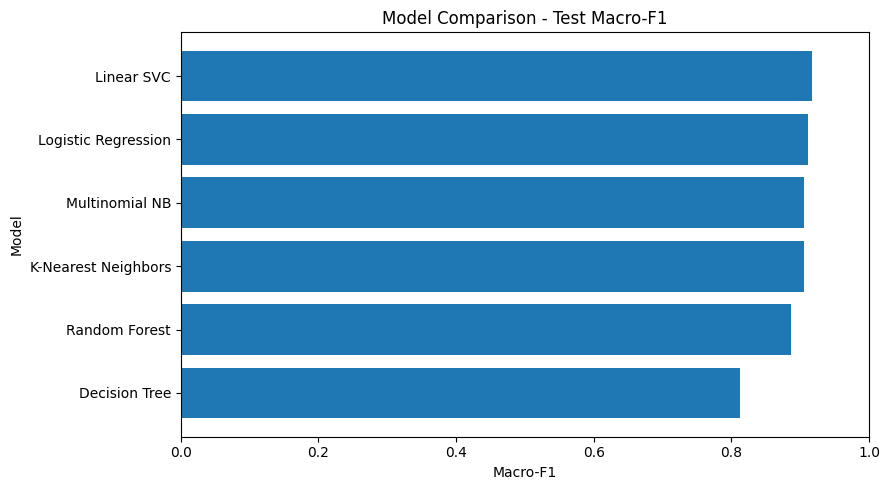

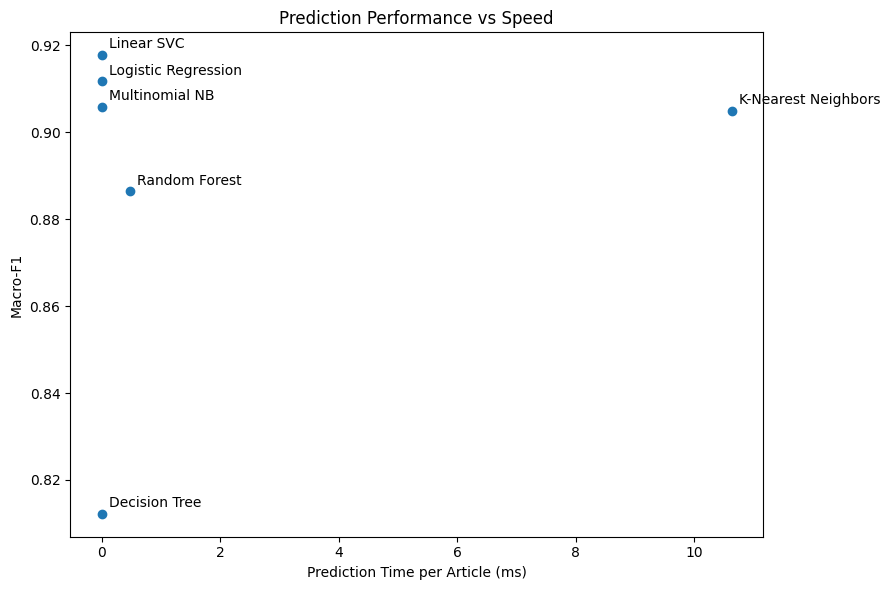

In [ ]:
import matplotlib.pyplot as plt

# Graph 1 : Test results based on macro f1
plot_data = test_results_df.sort_values(by="Macro-F1", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(plot_data["Model"], plot_data["Macro-F1"])
plt.xlabel("Macro-F1")
plt.ylabel("Model")
plt.title("Model Comparison - Test Macro-F1")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()


# Graph 2: Macro-F1 vs prediction time
plt.figure(figsize=(9, 6))
plt.scatter(test_results_df["Time per Article (ms)"],test_results_df["Macro-F1"])

for _, row in test_results_df.iterrows():
    plt.annotate(
        row["Model"],
        (
            row["Time per Article (ms)"],
            row["Macro-F1"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Prediction Time per Article (ms)")
plt.ylabel("Macro-F1")
plt.title("Prediction Performance vs Speed")

plt.tight_layout()
plt.show()


In [ ]:
# Take validation score
best_validation_scores = (tuning_df.loc[tuning_df.groupby("Model")["Macro-F1"].idxmax(), ["Model", "Macro-F1"]].rename(columns={"Macro-F1": "Validation Macro-F1"}))

# Join with test score
validation_test_comparison = best_validation_scores.merge(test_results_df[["Model", "Macro-F1"]], on="Model")
validation_test_comparison = validation_test_comparison.rename(columns={"Macro-F1": "Test Macro-F1"})
validation_test_comparison["Score Difference"] = (validation_test_comparison["Validation Macro-F1"] - validation_test_comparison["Test Macro-F1"])

# At this point, we would like to see is there any gap between validation and test score to ensure no overfitting
display(validation_test_comparison.sort_values(by="Test Macro-F1", ascending=False).reset_index(drop=True))

,Model,Validation Macro-F1,Test Macro-F1,Score Difference
0,Linear SVC,0.917993,0.917706,0.000287
1,Logistic Regression,0.916086,0.911674,0.004412
2,Multinomial NB,0.909200,0.905771,0.003429
3,K-Nearest Neighbors,0.906743,0.904949,0.001794
4,Random Forest,0.888282,0.886371,0.001911
5,Decision Tree,0.811419,0.812215,-0.000796


In [ ]:
from sklearn.metrics import classification_report

# Select the final model using validation performance, not test performance (test perfomance only will be conducted later after choosing the model)
best_model_name = best_models_df.iloc[0]["Model"]
best_model = best_models[best_model_name]
best_pred = test_predictions[best_model_name]

# Define class names in the same order as the numeric labels
class_names = [
    "World",
    "Sports",
    "Business",
    "Sci/Tech"
]

print("Selected model (based on validation Macro-F1):", best_model_name)
print()

# Generate the classification report on the held-out test set
print(
    classification_report(
        y_test,
        best_pred,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)


Selected model (based on validation Macro-F1): Linear SVC

              precision    recall  f1-score   support

       World       0.93      0.90      0.92      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.89      0.88      0.88      1900
    Sci/Tech       0.89      0.91      0.90      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



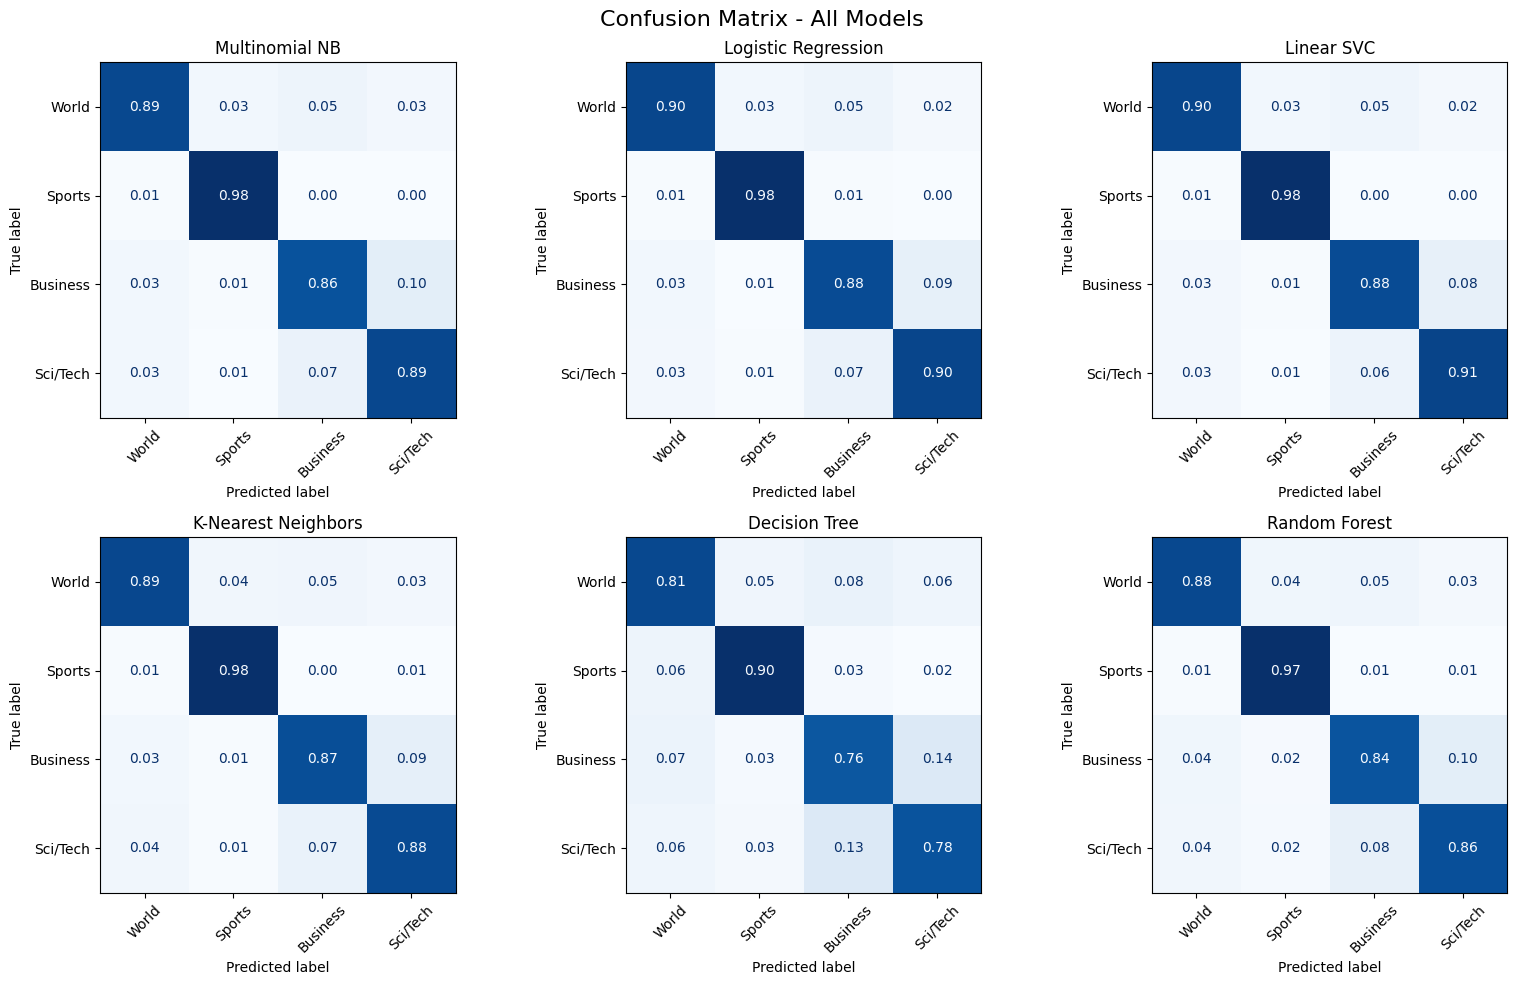

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Create grid 2 x 3
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, prediction) in enumerate(test_predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediction,
        labels=[0, 1, 2, 3],
        display_labels=class_names,
        normalize="true",
        cmap="Blues",
        values_format=".2f",
        ax=axes[i],
        colorbar=False
    )
    axes[i].set_title(name)
    axes[i].tick_params(axis="x", rotation=45)

# Hide subplots that are not used
for j in range(len(test_predictions), len(axes)):
    axes[j].axis("off")

plt.suptitle("Confusion Matrix - All Models", fontsize=16)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
# Error test (We want to check what's error that might happens in our codes)
actual_labels = np.asarray(y_test)
predicted_labels = np.asarray(best_pred)

wrong_positions = np.where(actual_labels != predicted_labels)[0]
error_analysis = df_test.iloc[wrong_positions].copy()
error_analysis["Actual Category"] = [label_mapping[label] for label in actual_labels[wrong_positions]]
error_analysis["Predicted Category"] = [label_mapping[label] for label in predicted_labels[wrong_positions]]

# Show error analysis -> 10
error_analysis = error_analysis[
    [
        "text",
        "Actual Category",
        "Predicted Category"
    ]
].head(10)

display(error_analysis)

,text,Actual Category,Predicted Category
20,IBM to hire even more new workers By the end o...,Sci/Tech,Business
23,Some People Not Eligible to Get in on Google I...,Sci/Tech,Business
24,Rivals Try to Turn Tables on Charles Schwab By...,Sci/Tech,Business
36,Venezuela Prepares for Chavez Recall Vote Supp...,World,Business
56,India's Tata expands regional footprint via Na...,World,Business
79,Live: Olympics day four Richard Faulds and Ste...,World,Sports
83,Intel to delay product aimed for high-definiti...,Business,Sci/Tech
106,Stocks Climb on Drop in Consumer Prices NEW YO...,World,Business
110,Yahoo! Ups Ante for Small Businesses Web giant...,Business,Sci/Tech
120,Oil prices bubble to record high The price of ...,World,Business


In [ ]:
import pickle

# Calculate model sizes
model_sizes = []

for name, model in best_models.items():

    model_bytes = pickle.dumps(model)
    size_mb = len(model_bytes) / (1024 ** 2)

    model_sizes.append({"Model": name, "Model Size (MB)": size_mb})

model_sizes_df = pd.DataFrame(model_sizes)
final_comparison = test_results_df.merge(model_sizes_df, on="Model")

final_comparison = final_comparison.sort_values(by="Macro-F1", ascending=False).reset_index(drop=True)

display(final_comparison)

,Model,Macro-F1,Accuracy,Macro Precision,Macro Recall,Prediction Time (s),Time per Article (ms),Model Size (MB)
0,Linear SVC,0.917706,0.917895,0.917828,0.917895,0.003750,0.000493,1.526504
1,Logistic Regression,0.911674,0.911842,0.911734,0.911842,0.009042,0.001190,1.526607
2,Multinomial NB,0.905771,0.906053,0.905907,0.906053,0.010398,0.001368,3.052392
3,K-Nearest Neighbors,0.904949,0.905263,0.904931,0.905263,80.793371,10.630707,32.958130
4,Random Forest,0.886371,0.886842,0.886329,0.886842,3.657907,0.481304,471.208980
5,Decision Tree,0.812215,0.812368,0.812091,0.812368,0.028558,0.003758,2.144654


### Probability Calibration
Linear SVC is the strongest classical model, but it does not provide `predict_proba`, so it cannot give the confidence score that the proposal that we proposed requires. Sigmoid (Platt) calibration is therefore fitted with 3-fold cross-validation inside the fit set only, so the validation and test sets stay untouched.

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

# 1. Wrap the best Linear SVC configuration with sigmoid calibration
best_svc_c = best_models["Linear SVC"].C

calibrated_svc = CalibratedClassifierCV(
    LinearSVC(C=best_svc_c, max_iter=2000, random_state=42),
    method="sigmoid",
    cv=3
)

# 2. Training (the calibration folds come from the fit set only)
start_train = time.time()
calibrated_svc.fit(x_fit_tfidf, y_fit)
calibrated_training_time = time.time() - start_train

# 3. Prediction on validation and test set
val_pred_calibrated = calibrated_svc.predict(x_val_tfidf)

start_predict = time.time()
test_pred_calibrated = calibrated_svc.predict(x_test_tfidf)
calibrated_prediction_time = time.time() - start_predict

# 4. Save the result in the same format as the other models
calibrated_result = {
    "Model": "Linear SVC (Calibrated)",
    "Macro-F1": f1_score(y_test, test_pred_calibrated, average="macro"),
    "Accuracy": accuracy_score(y_test, test_pred_calibrated),
    "Macro Precision": precision_score(y_test, test_pred_calibrated, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, test_pred_calibrated, average="macro", zero_division=0),
    "Prediction Time (s)": calibrated_prediction_time,
    "Time per Article (ms)": (calibrated_prediction_time / len(y_test)) * 1000,
    "Model Size (MB)": len(pickle.dumps(calibrated_svc)) / (1024 ** 2),
    "Training Time (s)": calibrated_training_time
}

print(f"Best C from tuning        : {best_svc_c}")
print(f"Training time             : {calibrated_training_time:.2f} seconds")
print(f"Validation Macro-F1       : {f1_score(y_val, val_pred_calibrated, average='macro'):.4f}")
print(f"Test Macro-F1             : {calibrated_result['Macro-F1']:.4f}")
print(f"Uncalibrated Test Macro-F1: {f1_score(y_test, test_predictions['Linear SVC'], average='macro'):.4f}")

Best C from tuning        : 0.5
Training time             : 45.99 seconds
Validation Macro-F1       : 0.9183
Test Macro-F1             : 0.9158
Uncalibrated Test Macro-F1: 0.9177


### Probability Quality: Log-loss and ROC-AUC
Log-loss measures how well the predicted probabilities match the true labels (lower is better). ROC-AUC (one-vs-rest, macro average) measures how well the probabilities rank the correct desk above the others (higher is better). Only models that can produce probabilities are included.

In [ ]:
from sklearn.metrics import log_loss, roc_auc_score

# 1. Collect every model that can produce class probabilities
probability_models = {
    name: model
    for name, model in best_models.items()
    if hasattr(model, "predict_proba")
}

probability_models["Linear SVC (Calibrated)"] = calibrated_svc

# 2. Evaluate the probability quality on the test set
probability_results = []
test_probabilities = {}

for name, model in probability_models.items():
    probabilities = model.predict_proba(x_test_tfidf)
    test_probabilities[name] = probabilities

    probability_results.append({
        "Model": name,
        "Log-loss": log_loss(y_test, probabilities, labels=model.classes_),
        "ROC-AUC (OvR)": roc_auc_score(y_test, probabilities, multi_class="ovr", average="macro", labels=model.classes_)
    })

# 3. Print result on the probability table
probability_results_df = pd.DataFrame(probability_results)
probability_results_df = probability_results_df.sort_values(by="Log-loss").reset_index(drop=True)
display(probability_results_df)

,Model,Log-loss,ROC-AUC (OvR)
0,Linear SVC (Calibrated),0.268391,0.982348
1,Logistic Regression,0.299426,0.981217
2,Multinomial NB,0.362358,0.978316
3,Random Forest,0.401143,0.975517
4,K-Nearest Neighbors,0.508649,0.980377
5,Decision Tree,6.758459,0.874970


- **Linear SVC (Calibrated)** gives the best probability quality (lowest log-loss, highest ROC-AUC), while its Macro-F1 is only slightly lower than the uncalibrated Linear SVC.
- **Decision Tree** has a very high log-loss because a fully grown tree almost always predicts a probability of 1.0, so every mistake is extremely confident.
- **K-Nearest Neighbors** ranks the desks well (high ROC-AUC), but its probabilities are less reliable (higher log-loss) than the linear models.

### Confidence-Based Routing (Coverage at ≥ 95% Accuracy)
This answers the second half of the research question: how much editorial work can be removed safely. An article is **auto-filed** when the model confidence (highest class probability) is at least the threshold; otherwise it is sent to an editor.

1. For every model and threshold, coverage and auto-filed accuracy are calculated on the **validation set**.
2. The selected threshold is the lowest one that keeps auto-filed accuracy at or above 95%, because it gives the highest coverage.
3. That threshold is applied **unchanged** to the test set, so the test set is never used to choose it.

In [ ]:
# 1. Candidate confidence thresholds and the business target
thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]
TARGET_ACCURACY = 0.95

y_val_array = np.asarray(y_val)

# 2. Coverage and auto-filed accuracy for each threshold on the VALIDATION set
routing_curve = []

for name, model in probability_models.items():
    val_probabilities = model.predict_proba(x_val_tfidf)
    confidence = val_probabilities.max(axis=1)
    prediction = model.classes_[val_probabilities.argmax(axis=1)]

    for threshold in thresholds:
        auto_filed = confidence >= threshold

        if auto_filed.any():
            auto_accuracy = accuracy_score(y_val_array[auto_filed], prediction[auto_filed])
        else:
            auto_accuracy = 0

        routing_curve.append({
            "Model": name,
            "Threshold": threshold,
            "Coverage": auto_filed.mean(),
            "Auto-filed Accuracy": auto_accuracy
        })

routing_curve_df = pd.DataFrame(routing_curve)

# 3. Choose the lowest threshold that keeps validation accuracy >= 95%
selected_thresholds = (
    routing_curve_df[routing_curve_df["Auto-filed Accuracy"] >= TARGET_ACCURACY]
    .sort_values(by=["Model", "Threshold"])
    .groupby("Model")
    .first()
    .reset_index()
)

display(selected_thresholds)

not_reached = set(probability_models) - set(selected_thresholds["Model"])
print("Models that never reach 95% accuracy on validation:", ", ".join(sorted(not_reached)) if not_reached else "-")

,Model,Threshold,Coverage,Auto-filed Accuracy
0,K-Nearest Neighbors,0.65,0.865884,0.950048
1,Linear SVC (Calibrated),0.70,0.902682,0.952642
2,Logistic Regression,0.65,0.877871,0.952258
3,Multinomial NB,0.85,0.871752,0.951250
4,Random Forest,0.70,0.748030,0.956858


Models that never reach 95% accuracy on validation: Decision Tree


In [ ]:
# Apply the validation-selected threshold unchanged to the TEST set
y_test_array = np.asarray(y_test)
routing_results = []

for _, row in selected_thresholds.iterrows():
    name = row["Model"]
    threshold = row["Threshold"]

    probabilities = test_probabilities[name]
    confidence = probabilities.max(axis=1)
    prediction = probability_models[name].classes_[probabilities.argmax(axis=1)]
    auto_filed = confidence >= threshold

    routing_results.append({
        "Model": name,
        "Threshold (from validation)": threshold,
        "Validation Coverage": row["Coverage"],
        "Validation Auto-filed Accuracy": row["Auto-filed Accuracy"],
        "Test Coverage": auto_filed.mean(),
        "Test Auto-filed Accuracy": accuracy_score(y_test_array[auto_filed], prediction[auto_filed]),
        "Sent to Editor (%)": (1 - auto_filed.mean()) * 100
    })

routing_results_df = pd.DataFrame(routing_results)
routing_results_df = routing_results_df.sort_values(by="Test Coverage", ascending=False).reset_index(drop=True)
display(routing_results_df)

,Model,Threshold (from validation),Validation Coverage,Validation Auto-filed Accuracy,Test Coverage,Test Auto-filed Accuracy,Sent to Editor (%)
0,Linear SVC (Calibrated),0.70,0.902682,0.952642,0.902237,0.950270,9.776316
1,Logistic Regression,0.65,0.877871,0.952258,0.877237,0.948853,12.276316
2,K-Nearest Neighbors,0.65,0.865884,0.950048,0.867895,0.947241,13.210526
3,Multinomial NB,0.85,0.871752,0.951250,0.867763,0.948446,13.223684
4,Random Forest,0.70,0.748030,0.956858,0.750132,0.953692,24.986842


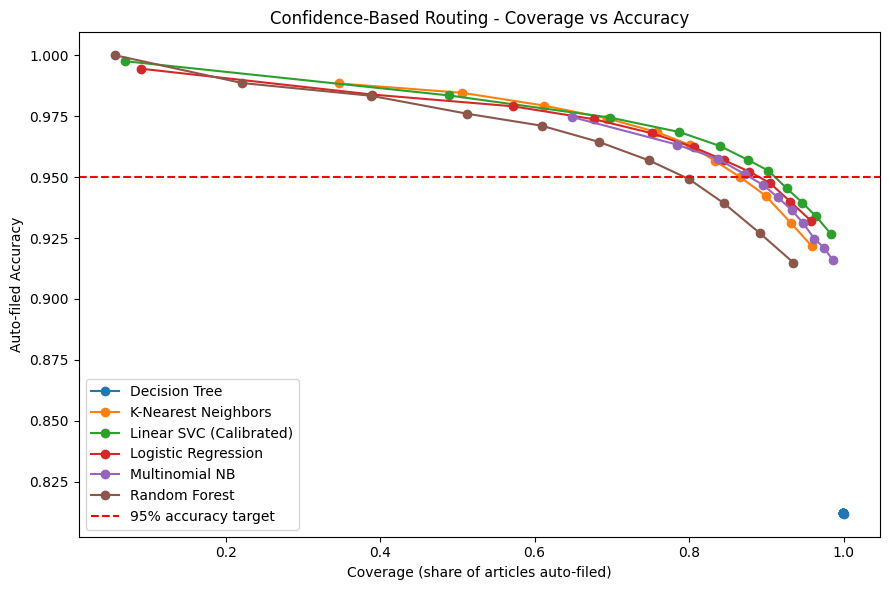

In [ ]:
# Visualize the trade-off between coverage and auto-filed accuracy (validation set)
plt.figure(figsize=(9, 6))

for name, group in routing_curve_df.groupby("Model"):
    plt.plot(group["Coverage"], group["Auto-filed Accuracy"], marker="o", label=name)

plt.axhline(TARGET_ACCURACY, color="red", linestyle="--", label="95% accuracy target")

plt.xlabel("Coverage (share of articles auto-filed)")
plt.ylabel("Auto-filed Accuracy")
plt.title("Confidence-Based Routing - Coverage vs Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

**Routing result**

- **Linear SVC (Calibrated)** gives the highest coverage. With the 0.70 threshold chosen on validation, about 90% of the test articles are auto-filed with 95.0% accuracy, and only about 10% are sent to editors.
- Logistic Regression, KNN, and Multinomial NB reach 95% on validation but fall slightly below 95% on the test set. This shows that a threshold chosen on validation is an estimate, not a guarantee.
- Random Forest stays above 95% but auto-files only about 75% of the articles.
- Decision Tree never reaches 95%, because its confidence is almost always 1.0, so the threshold cannot separate certain from uncertain articles.

**Recommendation for NewsLens:** Linear SVC (Calibrated) with a 0.70 confidence threshold. This value can be used as the default threshold in the Streamlit app.

In [ ]:
# Combine all evaluation results into one final table
training_times = best_models_df[["Model", "Training Time (s)"]]

final_summary = final_comparison.merge(training_times, on="Model", how="left")
final_summary = pd.concat([final_summary, pd.DataFrame([calibrated_result])], ignore_index=True)

final_summary = final_summary.merge(probability_results_df, on="Model", how="left")
final_summary = final_summary.merge(
    routing_results_df[["Model", "Threshold (from validation)", "Test Coverage", "Test Auto-filed Accuracy"]],
    on="Model",
    how="left"
)

final_summary = final_summary.sort_values(by="Macro-F1", ascending=False).reset_index(drop=True)
display(final_summary.round(4))

,Model,Macro-F1,Accuracy,Macro Precision,Macro Recall,Prediction Time (s),Time per Article (ms),Model Size (MB),Training Time (s),Log-loss,ROC-AUC (OvR),Threshold (from validation),Test Coverage,Test Auto-filed Accuracy
0,Linear SVC,0.9177,0.9179,0.9178,0.9179,0.0037,0.0005,1.5265,10.8213,NaN,NaN,NaN,NaN,NaN
1,Linear SVC (Calibrated),0.9158,0.9159,0.9159,0.9159,0.0250,0.0033,4.5798,45.9906,0.2684,0.9823,0.70,0.9022,0.9503
2,Logistic Regression,0.9117,0.9118,0.9117,0.9118,0.0090,0.0012,1.5266,24.4271,0.2994,0.9812,0.65,0.8772,0.9489
3,Multinomial NB,0.9058,0.9061,0.9059,0.9061,0.0104,0.0014,3.0524,0.0518,0.3624,0.9783,0.85,0.8678,0.9484
4,K-Nearest Neighbors,0.9049,0.9053,0.9049,0.9053,80.7934,10.6307,32.9581,0.0169,0.5086,0.9804,0.65,0.8679,0.9472
5,Random Forest,0.8864,0.8868,0.8863,0.8868,3.6579,0.4813,471.2090,503.4058,0.4011,0.9755,0.70,0.7501,0.9537
6,Decision Tree,0.8122,0.8124,0.8121,0.8124,0.0286,0.0038,2.1447,207.0618,6.7585,0.8750,NaN,NaN,NaN


## 7. Saving Project, so it's accessible via Link

In [ ]:
# We will drive to save the result especially for Random Forest because it's too large
from google.colab import drive
import os

drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
# Create folder to save the project result
FOLDER = "/content/drive/MyDrive/news-lens/models"

os.makedirs(FOLDER, exist_ok=True)

print("Folder ready:", FOLDER)

Folder ready: /content/drive/MyDrive/news-lens/models


In [ ]:
# Saved for TF-IDF
import joblib

path_vectorizer = os.path.join(FOLDER, "vectorizer.joblib")
joblib.dump(vectorizer, path_vectorizer, compress=3)

print("Vectorizer saved!")
print("Location:", path_vectorizer)


Vectorizer saved!
Location: /content/drive/MyDrive/news-lens/models/vectorizer.joblib


In [ ]:
for name, model in best_models.items():

    file_name = name.lower().replace(" ", "_") + ".joblib"
    path_file = os.path.join(FOLDER, file_name)

    joblib.dump(model, path_file, compress=3)
    size_mb = os.path.getsize(path_file) / (1024 * 1024)

    print(f"Saved: {file_name} ({size_mb:.2f} MB)")



Saved: multinomial_nb.joblib (1.89 MB)
Saved: logistic_regression.joblib (1.46 MB)
Saved: linear_svc.joblib (1.47 MB)
Saved: k-nearest_neighbors.joblib (26.08 MB)
Saved: decision_tree.joblib (0.48 MB)
Saved: random_forest.joblib (105.92 MB)


In [ ]:
import json

path_mapping = os.path.join(FOLDER, "label_mapping.json")

with open(path_mapping, "w") as f:
    json.dump(label_mapping, f, indent=2)

print("Label mapping saved!")


Label mapping saved!


In [ ]:
path_test_results = os.path.join(FOLDER, "test_results.csv")
test_results_df.to_csv(path_test_results, index=False)

print("Test result saved!")


Test result saved!


In [ ]:
# Save the calibrated Linear SVC, the routing result, and the final summary
path_calibrated = os.path.join(FOLDER, "linear_svc_calibrated.joblib")
joblib.dump(calibrated_svc, path_calibrated, compress=3)

routing_results_df.to_csv(os.path.join(FOLDER, "routing_results.csv"), index=False)
final_summary.to_csv(os.path.join(FOLDER, "final_summary.csv"), index=False)

size_mb = os.path.getsize(path_calibrated) / (1024 * 1024)
print(f"Saved: linear_svc_calibrated.joblib ({size_mb:.2f} MB)")
print("Routing result and final summary saved!")

Saved: linear_svc_calibrated.joblib (4.40 MB)
Routing result and final summary saved!


In [ ]:
import sys
import sklearn
import numpy
import joblib
import pandas

versions = f"""
Python       : {sys.version.split()[0]}
scikit-learn : {sklearn.__version__}
numpy        : {numpy.__version__}
joblib       : {joblib.__version__}
pandas       : {pandas.__version__}
"""
print(versions)


Python       : 3.13.18
scikit-learn : 1.6.1
numpy        : 2.4.6
joblib       : 1.6.0
pandas       : 2.2.3



In [ ]:
!cd "/content/drive/MyDrive/news-lens" && zip -r /content/models.zip models

  adding: models/ (stored 0%)
  adding: models/vectorizer.joblib (deflated 0%)
  adding: models/multinomial_nb.joblib (deflated 0%)
  adding: models/logistic_regression.joblib (deflated 0%)
  adding: models/linear_svc.joblib (deflated 0%)
  adding: models/decision_tree.joblib (deflated 1%)
  adding: models/random_forest.joblib (deflated 1%)
  adding: models/label_mapping.json (deflated 23%)
  adding: models/test_results.csv (deflated 48%)
  adding: models/distilbert-agnews/ (stored 0%)
  adding: models/distilbert-agnews/config.json (deflated 51%)
  adding: models/distilbert-agnews/model.safetensors (deflated 8%)
  adding: models/distilbert-agnews/tokenizer_config.json (deflated 43%)
  adding: models/distilbert-agnews/tokenizer.json (deflated 71%)
  adding: models/distilbert-agnews/training_args.bin (deflated 53%)
  adding: models/distilbert_test_results.csv (deflated 20%)
  adding: models/distilbert_classification_report.csv (deflated 53%)
  adding: models/final_comparison.csv (deflate

In [ ]:
from google.colab import files

files.download("/content/models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>